In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from scipy.stats import ks_2samp, anderson_ksamp

import warnings
import tqdm

## Reading samples

In [12]:
harps = pd.read_csv('harps_final_for_feh.csv')
apogee = pd.read_csv('apogee_final_for_feh.csv')
galah = pd.read_csv('galah_final_for_feh.csv')


print (f'harps contains {len(harps)} stars')
print (f'apogee contains {len(apogee)} stars')    
print (f'galah contains {len(galah)} stars')

harps contains 798 stars
apogee contains 45727 stars
galah contains 71591 stars


In [13]:
PRETTY_LABELS = {
    "U_lsr":        r"$U_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "V_lsr":        r"$V_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "W_lsr":        r"$W_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UV_lsr":       r"$UV_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UW_lsr":       r"$UW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "VW_lsr":       r"$VW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UVW_lsr":      r"$UVW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "abs_U_lsr":    r"$|U|_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "abs_W_lsr":    r"$|W|_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "P_gal":        r"$P_{\mathrm{gal}}\,[\%]$",
    "rapo":         r"$R_{\mathrm{apo}}\,[\mathrm{kpc}]$",
    "rperi":        r"$R_{\mathrm{peri}}\,[\mathrm{kpc}]$",
    "zmax":         r"$Z_{\max}\,[\mathrm{kpc}]$",
    "eccentricity": r"$e$",
    "R_mean":       r"$R_{\mathrm{mean}}\,[\mathrm{kpc}]$",
}

In [14]:
def compare_dfs_by_source_id(df1, df2, label1='df1', label2='df2', id_col='source_id'):
    """
    Crossmatches two DataFrames by source_id and compares common numeric columns.
    
    Parameters:
        df1, df2: pandas DataFrames
        label1, label2: labels used for suffixes and reporting
        id_col: column to match on (default: 'source_id')
    
    Returns:
        merged_df: merged DataFrame with suffixes
        comparison_df: DataFrame with mean and max absolute differences per column
    """
    # Ensure ID column is string to avoid mismatches
    df1 = df1.copy()
    df2 = df2.copy()
    df1[id_col] = df1[id_col].astype(int)
    df2[id_col] = df2[id_col].astype(int)
    
    # Merge
    merged_df = pd.merge(df1, df2, on=id_col, suffixes=(f'_{label1}', f'_{label2}'))
    print(f"Matched rows: {len(merged_df)} / {len(df1)} {label1.upper()} entries")
    
    # Get common columns
    common_cols = list(set(df1.columns) & set(df2.columns))
    
    # Compare only numeric columns
    comparison_stats = []
    for col in common_cols:
        col_1 = f"{col}_{label1}"
        col_2 = f"{col}_{label2}"
        if col_1 in merged_df.columns and col_2 in merged_df.columns:
            try:
                # Convert to numeric
                series_1 = pd.to_numeric(merged_df[col_1], errors='coerce')
                series_2 = pd.to_numeric(merged_df[col_2], errors='coerce')
                diff = (series_1 - series_2).abs()
                comparison_stats.append({
                    'column': col,
                    'mean_abs_diff': diff.mean(),
                    'max_abs_diff': diff.max(),
                    'n_nan': diff.isna().sum()
                })
            except Exception:
                continue

    comparison_df = pd.DataFrame(comparison_stats)
    comparison_df.sort_values(by='mean_abs_diff', ascending=False, inplace=True)
    
    return merged_df, comparison_df


In [15]:
def plot_element_minus_feh_vs_feh(dfs, element='mg_h', labels=None, colors=None):
    """
    Plots [X/H] - [Fe/H] vs [Fe/H] for 2 or 3 DataFrames, with mean [X/Fe] in [-0.1, 0.1] annotated.

    Parameters:
        dfs: list of 2 or 3 pandas DataFrames
        element: string, element column name (e.g., 'mg_h')
        labels: list of labels (same length as dfs)
        colors: list of colors (same length as dfs)
    """
    if not (2 <= len(dfs) <= 3):
        raise ValueError("Please provide 2 or 3 DataFrames.")

    if labels is None:
        labels = [f'DF{i+1}' for i in range(len(dfs))]
    if len(labels) != len(dfs):
        raise ValueError("Length of 'labels' must match number of DataFrames.")

    if colors is None:
        default_colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]
        colors = default_colors[:len(dfs)]

    fig, ax = plt.subplots(figsize=(10, 6))
    label_elem = element.split("_")[0].capitalize()
    y_offset = 0.05

    for i, (df, label, color) in enumerate(zip(dfs, labels, colors)):
        try:
            x = pd.to_numeric(df['fe_h'], errors='coerce')
            y = pd.to_numeric(df[element], errors='coerce')
            mask = x.notna() & y.notna()
            x = x[mask]
            y = y[mask]
            delta = y - x

            ax.scatter(x, delta, alpha=0.5, label=label, s=20, color=color)

            sel_mask = (x >= -0.1) & (x <= 0.1)
            if sel_mask.sum() >= 5:
                mean_val = delta[sel_mask].mean()
                ax.annotate(
                    f"{label}: {mean_val:.3f}",
                    xy=(0.05, 0.05 + i * y_offset),
                    xycoords='data',
                    color=color,
                    fontsize=10,
                    ha='left',
                    va='center',
                    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=color, lw=1)
                )
        except Exception as e:
            print(f"Skipping {label} due to error: {e}")

    ax.axhline(0, color='gray', linestyle='--', lw=1)
    ax.set_xlabel('[Fe/H]')
    ax.set_ylabel(f'[{label_elem}/Fe]')
    ax.set_title(f'[{label_elem}/Fe] vs [Fe/H]')
    ax.legend()
    ax.grid(True)
    plt.tight_layout()
    plt.show()


Skipping APOGEE due to error: 'mg_h'
Skipping GALAH due to error: 'mg_h'
Skipping HARPS due to error: 'mg_h'


/tmp/ipykernel_151225/3973873651.py:58: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


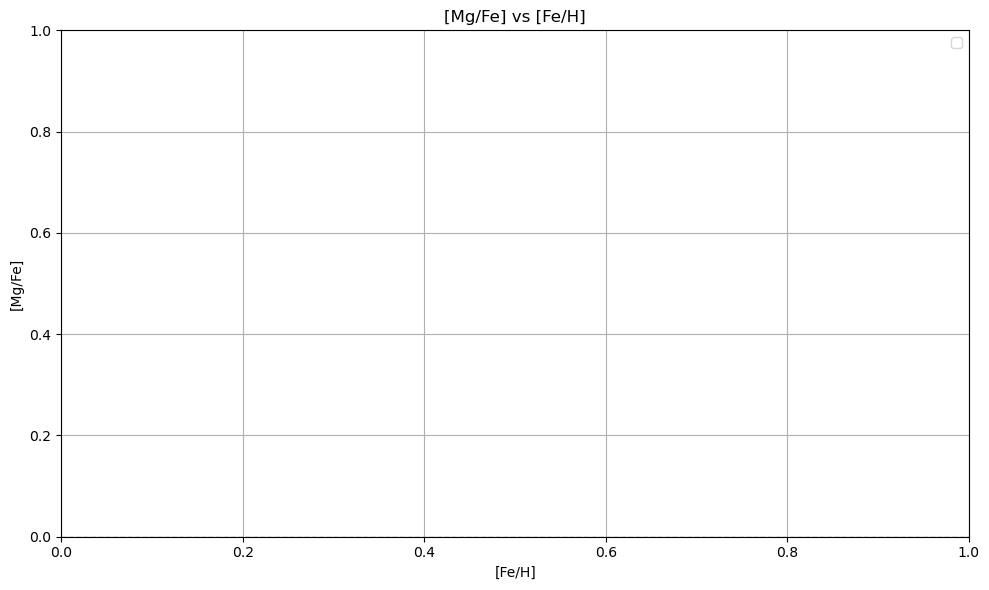

In [16]:
plot_element_minus_feh_vs_feh(
    dfs=[apogee, galah, harps],
    element='mg_h',
    labels=[ 'APOGEE', 'GALAH', 'HARPS']
)


In [17]:
apogee

,zmax,rperi,P_gal,eccentricity,rapo,V_lsr,W_lsr,UVW_lsr,U_lsr,fe_h
0,0.274214,10.903978,96.4,0.074567,12.661153,-7.89,-5.64,81.191341,-80.61,-0.08
1,0.398805,6.557123,97.3,0.226702,10.401738,-30.58,19.57,36.309247,-0.49,-0.28
2,0.523406,9.156036,94.9,0.121192,11.681365,-51.46,8.76,52.211041,-1.06,-0.26
3,0.450359,6.926147,95.4,0.132386,9.039817,-31.33,24.60,49.330912,-29.10,0.05
4,0.477434,7.004757,28.3,0.245409,11.560940,-66.80,2.25,131.700467,-113.48,0.03
...,...,...,...,...,...,...,...,...,...,...
45722,0.686282,9.081069,80.5,0.088757,10.850093,-37.18,-22.43,98.273307,-88.16,-0.15
45723,0.343546,9.495441,95.6,0.055250,10.606041,-26.68,-15.51,70.305273,-63.17,-0.10
45724,0.151643,8.433298,98.9,0.152603,11.470718,-10.07,7.32,25.522259,-22.28,-0.41
45725,1.537046,3.801275,7.8,0.465348,10.418345,-78.28,44.14,98.852872,41.18,-0.50


In [18]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

color_list_2 = ["#1f77b4", "#ff7f0e"]  # APOGEE, HARPS

def plot_distribution_duo(
    df1, df2, feature,
    labels=("APOGEE", "HARPS"),
    pretty_labels=None,               # <- pass PRETTY_LABELS here
    source_col="source",              # <- fixed grouping col
    palette=color_list_2,
    bins=30,
    clip_quantiles=(0.0, 1.0),        # e.g. (0.005, 0.995) if you want trimming
    kde=True,
    figsize=(7, 8),
    savepath=None,
    dpi=300,
    show=True
):
    """
    Two-panel comparison plot:
      (top) overlaid histograms (probability)
      (bottom) boxplot by dataset

    Uses pretty_labels[feature] if provided for axis labels.
    """

    # --- build combined dataset with labels
    df1_copy = df1.copy()
    df2_copy = df2.copy()
    df1_copy[source_col] = labels[0]
    df2_copy[source_col] = labels[1]
    data_df = pd.concat([df1_copy, df2_copy], ignore_index=True)

    # --- clean numeric feature
    data_df.replace([np.inf, -np.inf], np.nan, inplace=True)
    data_df = data_df[pd.to_numeric(data_df[feature], errors="coerce").notna()]
    data_df[feature] = data_df[feature].astype(float)

    # --- pretty axis label
    if pretty_labels is None:
        pretty_labels = {}
    xlab = pretty_labels.get(feature, feature)

    # --- plot
    f, axes = plt.subplots(2, 1, figsize=figsize)

    # histogram per dataset
    for i, s in enumerate(data_df[source_col].unique()):
        selection = data_df.loc[data_df[source_col] == s, feature].dropna()
        if len(selection) < 10:
            continue

        qlo, qhi = np.quantile(selection, clip_quantiles)
        selection = selection[(selection >= qlo) & (selection <= qhi)]

        with warnings.catch_warnings():
            warnings.simplefilter("ignore", category=FutureWarning)
            sns.histplot(
                selection,
                bins=bins,
                color=palette[i],
                ax=axes[0],
                label=s,
                kde=kde,
                stat="probability",
                element="step",
                fill=True,
                alpha=0.4,
            )

    # boxplot
    sns.boxplot(
        x=source_col, y=feature,
        data=data_df,
        palette=palette,
        ax=axes[1]
    )

    # labels
    axes[0].set_xlabel(xlab, fontsize=14)
    axes[0].set_ylabel("Probability", fontsize=14)
    axes[1].set_xlabel("")
    axes[1].set_ylabel(xlab, fontsize=14)

    # ticks
    for ax in axes:
        ax.tick_params(axis="both", which="major", labelsize=12, length=6, width=1.5)

    axes[0].legend(title="")
    plt.tight_layout()

    if savepath is not None:
        os.makedirs(os.path.dirname(savepath), exist_ok=True)
        plt.savefig(savepath, dpi=dpi)

    if show:
        plt.show()
    else:
        plt.close()

In [19]:
def plot_all_feature_distributions(
    df1, df2,
    features,
    labels=("APOGEE", "HARPS"),
    pretty_labels=None,
    outdir="./figures/feature_distributions",
    **kwargs
):
    """
    Makes one figure per feature and saves them to outdir.
    Any kwargs are passed to plot_distribution_duo.
    """
    os.makedirs(outdir, exist_ok=True)

    for feat in features:
        savepath = os.path.join(outdir, f"dist_{feat}.png")
        plot_distribution_duo(
            df1, df2,
            feature=feat,
            labels=labels,
            pretty_labels=pretty_labels,
            savepath=savepath,
            **kwargs
        )

In [20]:
FEATURES = apogee.columns

plot_all_feature_distributions(
    apogee, harps,
    features=FEATURES,
    labels=("APOGEE", "HARPS"),
    pretty_labels=PRETTY_LABELS,
    outdir="./figures/feature_distributions",
    bins=30,
    clip_quantiles=(0.0, 1.0),   # set to (0.005, 0.995) if you want to suppress extreme tails
    kde=True,
    show=False                   # set True if you want them displayed interactively
)

/tmp/ipykernel_151225/3608817409.py:77: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_151225/3608817409.py:77: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_151225/3608817409.py:77: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_151225/3608817409.py:77: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_151225/3608817409.py:77: FutureWa